# Day 1 · Notebook 4 — What does SLAM actually produce? A zoo of maps

A SLAM system outputs **camera poses** (the trajectory). With depth (RGB-D camera, LiDAR, or depth from MVS) we can turn those poses into different **map representations**. Each one is useful for a different job:

| representation | what it stores | good for |
|---|---|---|
| sparse points (COLMAP, ORB-SLAM) | distinctive 3D points + descriptors | **localisation** |
| dense point cloud | every measured surface point | visualisation, measuring |
| voxel grid | occupied 3D cells | 3D collision checking |
| TSDF → mesh | signed distance to the nearest surface | clean surfaces, rendering, AR |
| **2D occupancy grid** | $P(\text{occupied})$ per floor cell | **ground-robot path planning** (Day 2) |

Data: 60 frames of the *lounge* RGB-D sequence (Zhou & Koltun 2013) with their camera poses (here the poses are given, as if SLAM had produced them).

In [ ]:
# Colab: Open3D is not preinstalled (tested with 0.19 and 0.20)
!pip -q install open3d

In [1]:
import shutil
from pathlib import Path
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt
import plotly.graph_objects as go

DATA = next((p for p in [Path("data"), Path("../data")] if p.exists()), Path("data"))
LOUNGE = DATA / "lounge_rgbd"

if not (LOUNGE / "trajectory.log").exists():
    # Colab: download the full sequence from Open3D's GitHub (1.4 GB, ~1-2 min) and keep every 50th frame.
    # (Or just upload the 12 MB data/lounge_rgbd folder.)
    full = o3d.data.LoungeRGBDImages()
    (LOUNGE / "color").mkdir(parents=True, exist_ok=True); (LOUNGE / "depth").mkdir(exist_ok=True)
    lines = Path(full.trajectory_log_path).read_text().strip().splitlines()
    entries = [lines[i:i + 5] for i in range(0, len(lines), 5)]
    sel = list(range(0, len(entries), 50)); out = []
    for k, idx in enumerate(sel):
        f = int(entries[idx][0].split()[2])
        o3d.io.write_image(str(LOUNGE / f"color/{k:03d}.jpg"), o3d.io.read_image(full.color_paths[f - 1]), 90)
        shutil.copy(full.depth_paths[f - 1], LOUNGE / f"depth/{k:03d}.png")
        out += [f"{k} {k} {len(sel)}"] + entries[idx][1:]
    (LOUNGE / "trajectory.log").write_text("\n".join(out) + "\n")
    o3d.io.write_pinhole_camera_intrinsic(str(LOUNGE / "camera_primesense.json"), o3d.camera.PinholeCameraIntrinsic(
        o3d.camera.PinholeCameraIntrinsicParameters.PrimeSenseDefault))

intr = o3d.io.read_pinhole_camera_intrinsic(str(LOUNGE / "camera_primesense.json"))
K = intr.intrinsic_matrix
traj = o3d.io.read_pinhole_camera_trajectory(str(LOUNGE / "trajectory.log"))
T_cw = [p.extrinsic for p in traj.parameters]           # cam-from-world (what Open3D calls "extrinsic")
T_wc = [np.linalg.inv(T) for T in T_cw]                 # world-from-cam (camera pose)
N = len(T_cw)
print(N, "frames\nK =\n", K)

def load_rgbd(i, depth_trunc=3.5):
    color = o3d.io.read_image(str(LOUNGE / f"color/{i:03d}.jpg"))
    depth = o3d.io.read_image(str(LOUNGE / f"depth/{i:03d}.png"))
    return o3d.geometry.RGBDImage.create_from_color_and_depth(
        color, depth, depth_scale=1000.0, depth_trunc=depth_trunc, convert_rgb_to_intensity=False)

def show(*traces, title="", height=600):
    fig = go.Figure(list(traces))
    fig.update_layout(scene=dict(aspectmode="data", camera=dict(up=dict(x=0, y=-1, z=0))),
                      height=height, title=title, margin=dict(l=0, r=0, t=40, b=0))
    fig.show()

def points_trace(P, C=None, n=80_000, size=1.5, name="points"):
    idx = np.random.default_rng(0).choice(len(P), min(n, len(P)), replace=False)
    col = None if C is None else [f"rgb({int(255*r)},{int(255*g)},{int(255*b)})" for r, g, b in C[idx]]
    return go.Scatter3d(x=P[idx, 0], y=P[idx, 1], z=P[idx, 2], mode="markers",
                        marker=dict(size=size, color=col), name=name)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
60 frames
K =
 [[525.    0.  319.5]
 [  0.  525.  239.5]
 [  0.    0.    1. ]]


## 1 · One depth image → a point cloud (back-projection)

Projection in reverse: pixel $(u, v)$ with depth $Z$ gives the point in the **camera** frame

$$ \mathbf{X}_c = Z \, K^{-1} \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = \begin{bmatrix} (u - c_x) Z / f_x \\ (v - c_y) Z / f_y \\ Z \end{bmatrix} $$

and the camera pose moves it into the **world**: $\mathbf{X}_w = R_{wc}\,\mathbf{X}_c + \mathbf{t}_{wc}$.

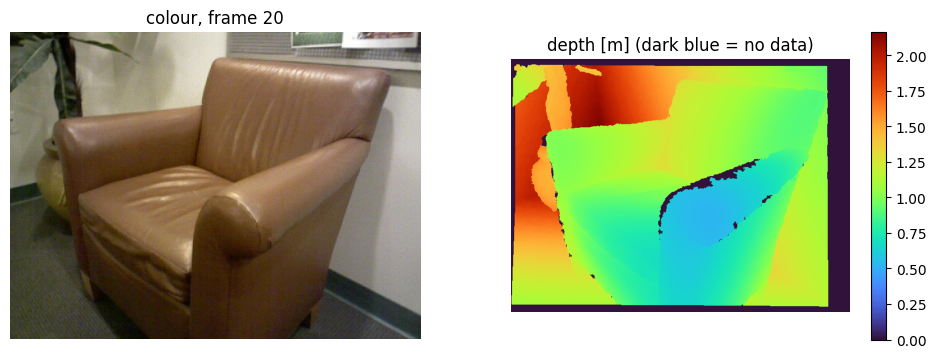

numpy: 264984 points   open3d: 264984 points   max difference: 8.88e-16 m


In [2]:
i = 20
rgbd = load_rgbd(i)
depth = np.asarray(rgbd.depth)                       # metres (0 = no measurement)
color = np.asarray(rgbd.color)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].imshow(color); axs[0].set_title(f"colour, frame {i}")
im = axs[1].imshow(depth, cmap="turbo"); axs[1].set_title("depth [m] (dark blue = no data)"); plt.colorbar(im, ax=axs[1])
for a in axs: a.axis("off")
plt.show()

# by hand, with numpy
v, u = np.nonzero(depth > 0)
Z = depth[v, u]
X_c = np.stack([(u - K[0, 2]) * Z / K[0, 0], (v - K[1, 2]) * Z / K[1, 1], Z], 1)
X_w = (T_wc[i][:3, :3] @ X_c.T).T + T_wc[i][:3, 3]
# with Open3D (same thing)
pcd_i = o3d.geometry.PointCloud.create_from_rgbd_image(rgbd, intr, T_cw[i])
print(f"numpy: {len(X_w)} points   open3d: {len(pcd_i.points)} points   "
      f"max difference: {np.abs(np.asarray(pcd_i.points) - X_w).max():.2e} m")

## 2 · All frames + poses → a dense point cloud

Stack every frame's points in the world frame. That's millions of points, so we **voxel-downsample**: one averaged point per 2 cm cube.

In [3]:
cloud = o3d.geometry.PointCloud()
for k in range(N):
    cloud += o3d.geometry.PointCloud.create_from_rgbd_image(load_rgbd(k), intr, T_cw[k])
print(f"raw: {len(cloud.points):,} points")
cloud = cloud.voxel_down_sample(0.02)
print(f"after 2 cm voxel downsampling: {len(cloud.points):,} points")

P, C = np.asarray(cloud.points), np.asarray(cloud.colors)
cams = np.array([T[:3, 3] for T in T_wc])
show(points_trace(P, C),
     go.Scatter3d(x=cams[:, 0], y=cams[:, 1], z=cams[:, 2], mode="lines+markers",
                  line=dict(color="red", width=5), marker=dict(size=2, color="red"), name="camera trajectory"),
     title="Dense point cloud + camera trajectory")

raw: 15,495,227 points
after 2 cm voxel downsampling: 293,925 points


## 3 · Voxel grid: occupied 3D cells

Throw away the exact positions and keep only **which cubes are occupied**. This gives constant-time collision checks ("is cell $(i,j,k)$ free?"), and it's the basis of OctoMap-style 3D maps used by drones.

In [4]:
for vs in [0.05, 0.10, 0.20]:
    vg = o3d.geometry.VoxelGrid.create_from_point_cloud(cloud, voxel_size=vs)
    print(f"voxel size {vs:.2f} m -> {len(vg.get_voxels()):6d} occupied voxels")

vg = o3d.geometry.VoxelGrid.create_from_point_cloud(cloud, voxel_size=0.10)
centers = np.array([vg.get_voxel_center_coordinate(v.grid_index) for v in vg.get_voxels()])
colors = np.array([v.color for v in vg.get_voxels()])
show(points_trace(centers, colors, size=4, name="voxels"), title="Voxel grid (10 cm), voxel centres")

voxel size 0.05 m ->  37054 occupied voxels
voxel size 0.10 m ->   9021 occupied voxels
voxel size 0.20 m ->   2212 occupied voxels


## 4 · TSDF fusion → a mesh (KinectFusion, Newcombe et al. 2011)

Each voxel $\mathbf{v}$ stores a **truncated signed distance** to the nearest surface along the viewing ray (positive in front, negative behind, clipped to $\pm\mu$), averaged over all frames:

$$ D(\mathbf{v}) \leftarrow \frac{W(\mathbf{v})\,D(\mathbf{v}) + w_k\, d_k(\mathbf{v})}{W(\mathbf{v}) + w_k}, \qquad W(\mathbf{v}) \leftarrow W(\mathbf{v}) + w_k $$

The surface is the **zero level set** $D = 0$, extracted with marching cubes. Averaging cancels depth noise, so you get much cleaner surfaces than the raw points.

In [5]:
# A dense cube of voxels around the room (3 cm voxels, ~1.4 GB RAM).
# (Open3D's ScalableTSDFVolume would use less memory, but it returns an empty mesh in v0.20.0.)
VOXEL = 0.03
lo3, hi3 = P.min(0) - 0.1, P.max(0) + 0.1
side = float((hi3 - lo3).max())
volume = o3d.pipelines.integration.UniformTSDFVolume(
    length=side, resolution=int(np.ceil(side / VOXEL)), sdf_trunc=0.10,
    color_type=o3d.pipelines.integration.TSDFVolumeColorType.RGB8, origin=lo3.reshape(3, 1))
for k in range(N):
    volume.integrate(load_rgbd(k), intr, T_cw[k])
mesh = volume.extract_triangle_mesh()
mesh.compute_vertex_normals()
print(mesh)

small = mesh.simplify_quadric_decimation(60_000)            # lighter for the browser
V, F, VC = np.asarray(small.vertices), np.asarray(small.triangles), np.asarray(small.vertex_colors)
show(go.Mesh3d(x=V[:, 0], y=V[:, 1], z=V[:, 2], i=F[:, 0], j=F[:, 1], k=F[:, 2],
               vertexcolor=[f"rgb({int(255*r)},{int(255*g)},{int(255*b)})" for r, g, b in VC], name="mesh"),
     title="TSDF mesh (60k triangles)")
o3d.io.write_triangle_mesh("lounge_mesh.ply", mesh)        # open it in MeshLab / Blender / Open3D on the laptop

TriangleMesh with 82287 points and 150262 triangles.


True

## 5 · Find the floor (RANSAC again!)

A ground robot needs to know which way is **up**. Fit a plane $\mathbf{n}^\top\mathbf{x} + d = 0$ with RANSAC: sample 3 points, fit, count inliers within 3 cm, repeat.

Cameras are held upright, so the camera's image-down axis (its $y$ axis) roughly points along gravity. We use that to check the plane really is the floor.

floor normal [-0.036 -0.999  0.011], cameras are 1.04 m above the floor


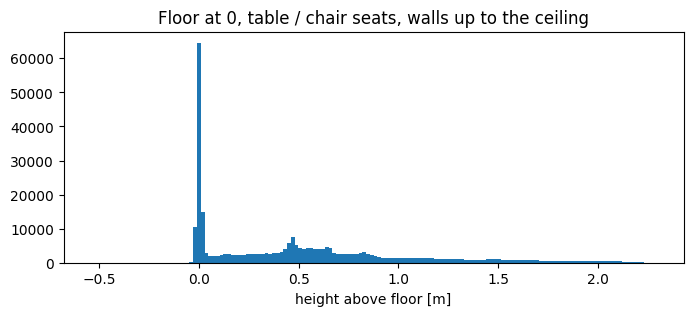

In [6]:
g = np.mean([T[:3, 1] for T in T_wc], axis=0); g /= np.linalg.norm(g)      # approx. gravity direction (world)
rest, plane = cloud, None
for _ in range(5):                                       # take the biggest plane that is horizontal
    (a, b, c, d), inl = rest.segment_plane(distance_threshold=0.03, ransac_n=3, num_iterations=2000)
    n = np.array([a, b, c])
    if abs(n @ g) > 0.9:
        plane = (n, d); break
    rest = rest.select_by_index(inl, invert=True)
n, d = plane
if np.mean(cams @ n + d) < 0:                            # orient the normal so cameras are on the + side
    n, d = -n, -d
height = P @ n + d                                       # height of every point above the floor [m]
print(f"floor normal {n.round(3)}, cameras are {np.mean(cams @ n + d):.2f} m above the floor")

plt.figure(figsize=(8, 3)); plt.hist(height, bins=150)
plt.xlabel("height above floor [m]"); plt.title("Floor at 0, table / chair seats, walls up to the ceiling"); plt.show()

## 6 · 2D occupancy grid with log-odds (the map a ground robot plans on)

Divide the floor into cells $m_i$. Keep the **log-odds** of each cell being occupied:

$$ l_i = \log\frac{p(m_i)}{1 - p(m_i)}, \qquad l_i \leftarrow l_i + \underbrace{\log\frac{p(m_i \mid z_t)}{1 - p(m_i \mid z_t)}}_{\text{inverse sensor model}} - l_0 $$

For every frame:
* points between 0.1 m and 1.5 m above the floor are **obstacles**: their cell gets $l_{\text{occ}} = +0.85$
* every cell along the ray from the camera to a measured point is **free**: $l_{\text{free}} = -0.4$

Adding is just Bayes' rule in log form (see Thrun, Burgard & Fox, *Probabilistic Robotics*, ch. 9). Get the probability back with $p = 1 - \frac{1}{1 + e^{l}}$.

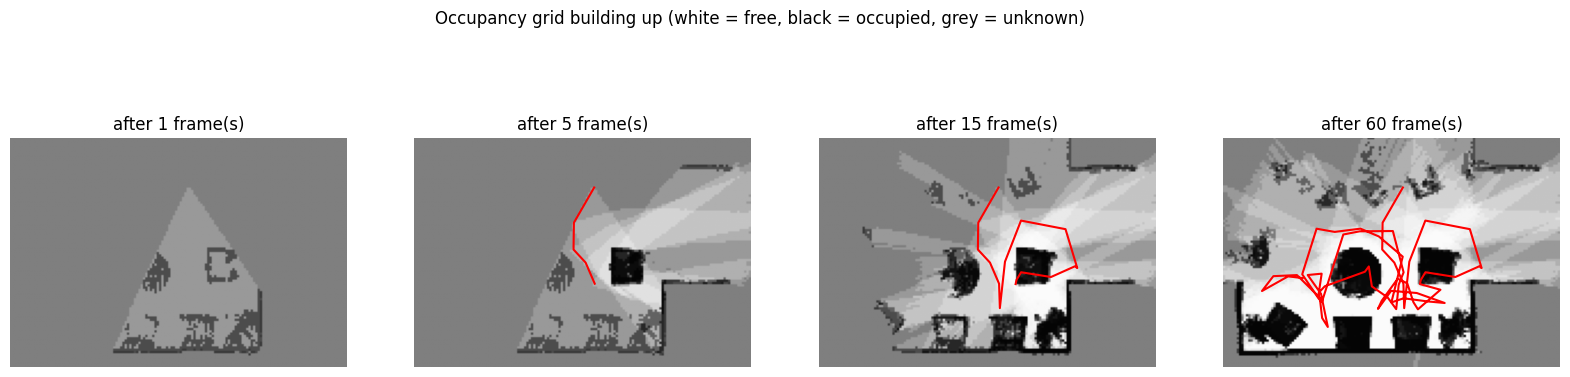

In [7]:
# floor-aligned 2D frame: two unit vectors orthogonal to the floor normal
e1 = np.cross(n, [0, 0, 1.0]); e1 /= np.linalg.norm(e1); e2 = np.cross(n, e1)
to2d = lambda X: np.stack([X @ e1, X @ e2], -1)

RES = 0.05                                               # 5 cm cells
xy_all = to2d(P)
lo = np.percentile(xy_all, 0.5, axis=0) - 0.3; hi = np.percentile(xy_all, 99.5, axis=0) + 0.3
W, H = np.ceil((hi - lo) / RES).astype(int)
cell = lambda xy: np.floor((xy - lo) / RES).astype(int)
L = np.zeros((W, H))
L_OCC, L_FREE, L_MIN, L_MAX = 0.85, -0.4, -4.0, 4.0
inside = lambda c: (c[:, 0] >= 0) & (c[:, 0] < W) & (c[:, 1] >= 0) & (c[:, 1] < H)

snapshots = []
for k in range(N):
    rgbd = load_rgbd(k, depth_trunc=4.0)
    Xk = np.asarray(o3d.geometry.PointCloud.create_from_rgbd_image(rgbd, intr, T_cw[k]).points)[::20]
    hk = Xk @ n + d
    obst = Xk[(hk > 0.10) & (hk < 1.5)]
    cam2d = to2d(T_wc[k][:3, 3])
    ends = to2d(Xk[hk < 1.5])                            # rays to floor + obstacle points
    t = np.linspace(0, 1, 120, endpoint=False)[None, :, None]
    ray_pts = cam2d[None, None, :] + t * (ends[:, None, :] - cam2d[None, None, :])
    free = cell(ray_pts.reshape(-1, 2)); free = np.unique(free[inside(free)], axis=0)
    occ = cell(to2d(obst)); occ = np.unique(occ[inside(occ)], axis=0)
    L[free[:, 0], free[:, 1]] += L_FREE                  # one update per cell per frame
    L[occ[:, 0], occ[:, 1]] += L_OCC - L_FREE            # (undo the free update on hit cells)
    np.clip(L, L_MIN, L_MAX, out=L)
    if k in (0, 4, 14, N - 1):
        snapshots.append((k, L.copy()))

prob = 1 - 1 / (1 + np.exp(L))
fig, axs = plt.subplots(1, len(snapshots), figsize=(5 * len(snapshots), 5))
for ax, (k, Lk) in zip(axs, snapshots):
    ax.imshow((1 - 1 / (1 + np.exp(Lk))).T, origin="lower", cmap="gray_r", vmin=0, vmax=1)
    c2 = (to2d(cams[:k + 1]) - lo) / RES
    ax.plot(c2[:, 0], c2[:, 1], "r-", lw=1.5); ax.set_title(f"after {k + 1} frame(s)"); ax.axis("off")
plt.suptitle("Occupancy grid building up (white = free, black = occupied, grey = unknown)"); plt.show()

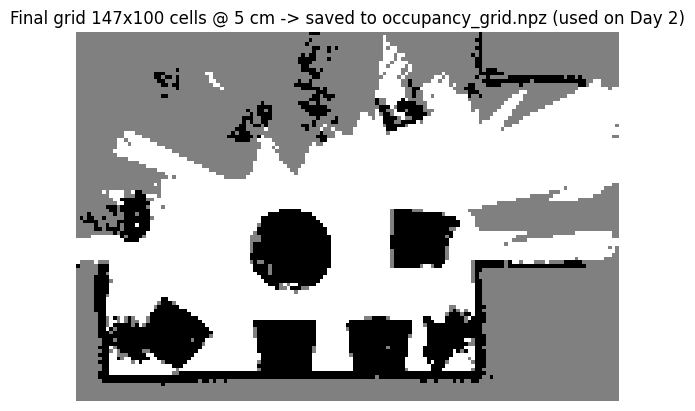

In [8]:
occ_grid = np.full(prob.shape, -1, np.int8)              # -1 unknown, 0 free, 1 occupied (ROS convention-ish)
occ_grid[prob < 0.3] = 0
occ_grid[prob > 0.7] = 1
cams_cells = (to2d(cams) - lo) / RES                       # camera positions in grid cells (x, y)
np.savez("occupancy_grid.npz", grid=occ_grid.T, prob=prob.T, resolution=RES, origin=lo, cams_cells=cams_cells)
plt.figure(figsize=(7, 6))
plt.imshow(np.where(occ_grid.T == -1, 0.5, 1 - occ_grid.T), origin="lower", cmap="gray", vmin=0, vmax=1)
plt.title(f"Final grid {W}x{H} cells @ {RES*100:.0f} cm -> saved to occupancy_grid.npz (used on Day 2)")
plt.axis("off"); plt.show()

## Summary: same room, five maps

| representation | size here | answers |
|---|---|---|
| sparse points (Notebooks 2 and 5) | thousands of points | "where am I?" (match features) |
| dense cloud | ~10⁵–10⁶ points | "what does it look like?" |
| voxel grid | ~10⁴ voxels | "is this 3D cell free?" |
| TSDF / mesh | ~10⁵ triangles | "where exactly is the surface?" |
| 2D occupancy grid | ~10⁴ cells | "where can a ground robot drive?" |

**Day 2:** localise in the sparse map, plan in the occupancy grid.